# Pilot: where does multi-dimensional angle encoding hit a precision limit — and are trainable frequencies worth it?

**Question.** With a fixed degree per feature (unary re-uploading, degree 5), the relative redundancy of the highest mixed-frequency cells falls geometrically with the input dimension $d$. At some $d$, the coefficient tangents of those cells fall below the floating-point floor and gradient-based training cannot move them. Where is that $d$, does it shift with precision as predicted, and do trainable prefactors change the picture?

**Design (everything native JAX, no PennyLane; one qubit per feature, Rot + CNOT ladder per layer, $Z$ readout on the last qubit).**

| Part | What it measures | Why it is a fair test |
|---|---|---|
| **A** Theory | Relative redundancy $\rho(\omega)=R(\omega)/R(0)$ of every lattice cell, exact, up to $d=16$ | Closed form; no circuit |
| **B** Representation | Row norms $r_\omega=\lVert\partial c_\omega/\partial\theta\rVert$ of the Fourier-coefficient Jacobian in **f32 and f64**, plus the noise floor measured from out-of-band cells (exactly zero in exact arithmetic) | Fits $\log_2 r_\omega = c+\gamma\log_2\rho_\omega$ across many $(d,L)$; the floor is measured, not assumed. **Precision-shift test:** one fitted line must predict *both* thresholds |
| **C** Training | Teacher–student with Adam and GD in f32 and f64; per-cell improvement $\lvert\Delta c^{\rm final}_\omega\rvert/\lvert\Delta c^{\rm init}_\omega\rvert$; test error for fixed vs trainable prefactors on lattice (T1) and off-lattice (T2) teachers | Teacher–student removes expressivity/controllability confounds: the target is exactly representable |

**Decision table (filled automatically in the last cell).**
1. Does tangent magnitude follow redundancy? → fitted $\gamma$ and collapse quality across $(d,L)$.
2. Does the precision law hold? → measured vs predicted threshold in f32 **and** f64 from one line.
3. Where is the limit at degree 5? → predicted $d^*$ (corner cell, 1 % and 50 % of cells) for unary/ternary, f32/f64.
4. Does the limit bind *training*? → per-cell improvement below vs above the predicted threshold, f32 vs f64. If f32 ≈ f64, something else (step budget/conditioning) binds first.
5. Are trainable frequencies worth it in higher $d$? → T2 test error trainable vs fixed as a function of $d$, and the cost on T1.

**Run modes.** `QUICK=True` (CPU, minutes) checks the pipeline; `QUICK=False` is the pilot proper (intended for `qtgpu`). Every part caches to `RESULTS_DIR` and resumes.

In [1]:
QUICK = False            # False on qtgpu for the actual pilot
RESULTS_DIR = "results_mdpilot_quick" if QUICK else "results_mdpilot"
SEED0 = 0

# Part B: (encoding, d, L) grid for the collapse / precision-shift test.
# Deep single-/two-qubit configs reach the f64 floor cheaply; the degree-5 cells give the practical curve.
if QUICK:
    PARTB_CONFIGS = [("unary", 1, L) for L in (3, 5, 10, 20, 40)] + \
                    [("unary", 2, L) for L in (3, 5, 8)] + [("unary", 3, 5)] + \
                    [("ternary", 1, 3), ("ternary", 2, 2)]
    PARTB_SEEDS = 2
else:
    PARTB_CONFIGS = [("unary", 1, L) for L in (3, 5, 8, 12, 16, 20, 25, 30, 40, 50)] + \
                    [("unary", 2, L) for L in (3, 5, 8, 12, 16, 20, 25)] + \
                    [("unary", 3, L) for L in (3, 5, 8, 10, 12, 15)] + \
                    [("unary", 4, L) for L in (3, 5, 8)] + [("unary", 5, 5)] + \
                    [("ternary", d, L) for d in (1, 2, 3) for L in (2, 3)] + [("ternary", 4, 2)]
    PARTB_SEEDS = 6
SNR_RESOLVED = 3.0      # a cell counts as resolved if r_omega > 3 x measured floor

# Part C
if QUICK:
    C_DIMS, C_STEPS, C_NTRAIN, C_NTEST, C_SEEDS = [1, 2, 3], 150, 256, 256, 2
    C_OPTS = {"adam": 0.01}
    C_STRESS = [(1, 30), (2, 12)]          # (d, L) where the f32 floor is predicted to bind
else:
    C_DIMS, C_STEPS, C_NTRAIN, C_NTEST, C_SEEDS = [1, 2, 3, 4, 5], 3000, 1024, 1024, 4
    C_OPTS = {"adam": 0.01, "gd": 0.05}    # GD lr is a first guess: check the loss curves
    C_STRESS = [(1, 30), (2, 12), (3, 8)]
C_PRECS = ["f32", "f64"]
C_INITS = ["near", "random"]   # near = teacher + 0.1 N(0,1): isolates 'can the optimiser pick up this direction'
C_SIGMA = 0.1
T2_JITTER = 0.3                # off-lattice teacher prefactors base*(1+U[-0.3,0.3])

import os; os.makedirs(RESULTS_DIR, exist_ok=True)

## Core: simulator, encodings, redundancy, coefficient Jacobian

In [2]:
# ---- core: simulator, encodings, coefficient Jacobian -------------------
import itertools, math, time, json, os
import numpy as np
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

PREC = {"f32": (jnp.float32, jnp.complex64), "f64": (jnp.float64, jnp.complex128)}

# Encodings: per-feature list of integer prefactors on successive re-uploads.
ENC = {
    "unary":   lambda L: [1] * L,                    # degree L, binomial redundancy
    "ternary": lambda L: [3 ** j for j in range(L)], # degree (3^L-1)/2, flat redundancy
}

def degree(alpha_base):
    return int(sum(abs(a) for a in alpha_base))

# ---------- gates (dtype follows the real input dtype) ----------
def _rx(a):
    c, s = jnp.cos(a / 2), jnp.sin(a / 2)
    return jnp.array([[c, -1j * s], [-1j * s, c]])

def _rot(p):  # RZ(w) RY(t) RZ(f), p = (f, t, w)
    f, t, w = p[0], p[1], p[2]
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    e = lambda z: jnp.exp(1j * z)
    return jnp.array([[e(-(f + w) / 2) * c, -e((f - w) / 2) * s],
                      [e(-(f - w) / 2) * s,  e((f + w) / 2) * c]])

def _apply_1q(psi, U, q):
    psi = jnp.tensordot(U, psi, axes=((1,), (q,)))
    return jnp.moveaxis(psi, 0, q)

def _apply_cnot(psi, c, t):
    p = jnp.moveaxis(psi, (c, t), (0, 1))
    p = jnp.stack([p[0], p[1][::-1]])
    return jnp.moveaxis(p, (0, 1), (c, t))

def model(x, theta, alpha):
    """Re-uploading circuit, one qubit per feature.
    x: (d,), theta: (L+1, d, 3), alpha: (L, d) prefactors.
    Layer: RX(alpha*x) on every qubit -> Rot on every qubit -> CNOT ladder.
    Readout: Z on the last qubit (ladder makes it a global parity readout)."""
    d = x.shape[0]; L = alpha.shape[0]
    cdt = jnp.complex64 if x.dtype == jnp.float32 else jnp.complex128
    psi = jnp.zeros((2,) * d, dtype=cdt).at[(0,) * d].set(1.0)
    for q in range(d):
        psi = _apply_1q(psi, _rot(theta[0, q]).astype(cdt), q)
    for l in range(L):
        for q in range(d):
            psi = _apply_1q(psi, _rx(alpha[l, q] * x[q]).astype(cdt), q)
        for q in range(d):
            psi = _apply_1q(psi, _rot(theta[l + 1, q]).astype(cdt), q)
        for q in range(d - 1):
            psi = _apply_cnot(psi, q, q + 1)
    pr = jnp.abs(psi) ** 2
    pr = pr.reshape(-1, 2)
    return jnp.sum(pr[:, 0] - pr[:, 1])

model_batch = jax.vmap(model, in_axes=(0, None, None))

def init_theta(key, L, d, rdt):
    return jax.random.uniform(key, (L + 1, d, 3), minval=0.0, maxval=2 * np.pi).astype(rdt)

def alpha_array(alpha_base, d, rdt):
    return jnp.tile(jnp.asarray(alpha_base, dtype=rdt)[:, None], (1, d))

# ---------- redundancy theory ----------
def redundancy_1d(alpha_base):
    """Eigenvalue-difference multiplicity per frequency for RX(a x) gates.
    Each gate contributes {-a:1, 0:2, +a:1}; normalised by 4^L. Returns (freqs, w)."""
    K = degree(alpha_base)
    w = np.zeros(2 * K + 1); w[K] = 1.0
    for a in alpha_base:
        new = np.zeros_like(w)
        for shift, m in ((-a, 1), (0, 2), (a, 1)):
            new += m * np.roll(w, shift)
        w = new
    return np.arange(-K, K + 1), w / 4.0 ** len(alpha_base)

def log2_rho_cells(alpha_base, d):
    """log2 of relative redundancy rho(omega) = R(omega)/R(0) for all cells of the d-dim lattice."""
    _, w = redundancy_1d(alpha_base)
    lw = np.log2(w / w.max())
    out = lw.copy()
    for _ in range(d - 1):
        out = (out[:, None] + lw[None, :]).ravel()
    return out

def log2_rho_hist(alpha_base, d, bins):
    """Histogram (cell counts) of log2 rho over the d-dim lattice via 1-D convolution of
    per-dimension histograms (exact up to binning; works for large d)."""
    _, w = redundancy_1d(alpha_base)
    lw = np.log2(w / w.max())
    width = bins[1] - bins[0]
    nb = len(bins) - 1
    h1 = np.zeros(nb)
    for v in lw:
        h1[min(int((v - bins[0]) / width), nb - 1)] += 1
    # work in "bin offset from top" coordinates so sums add
    top = nb - 1
    off1 = {top - i: c for i, c in enumerate(h1) if c}
    acc = {0: 1.0}
    for _ in range(d):
        new = {}
        for o, c in acc.items():
            for o1, c1 in off1.items():
                new[o + o1] = new.get(o + o1, 0.0) + c * c1
        acc = new
    return acc, width  # offset k (in bins) below top -> cell count

# ---------- coefficient Jacobian on an oversampled grid ----------
def grid_points(M, d, rdt):
    g = 2 * np.pi * np.arange(M) / M
    mesh = np.stack(np.meshgrid(*([g] * d), indexing="ij"), axis=-1).reshape(-1, d)
    return jnp.asarray(mesh, dtype=rdt)

_JAC = jax.jit(jax.vmap(jax.jacfwd(model, argnums=1), in_axes=(0, None, None)))
_FB = jax.jit(model_batch)

def coeff_jacobian_rows(theta, alpha, prec, chunk=4096):
    """Row norms r_omega = ||d c_omega / d theta|| of the Fourier-coefficient Jacobian,
    computed entirely in precision `prec`, on an oversampled grid M = 2K+3.
    Returns (freq_grid (M,)*d x d, r (M,)*d, inband mask, max|c|)."""
    rdt, cdt = PREC[prec]
    L, d = alpha.shape
    K = int(round(float(jnp.sum(jnp.abs(alpha[:, 0])))))
    M = 2 * K + 3
    X = grid_points(M, d, rdt)
    th = theta.astype(rdt); al = alpha.astype(rdt)
    jac_fn, f_fn = _JAC, _FB
    Js, fs = [], []
    for i in range(0, X.shape[0], chunk):
        Js.append(jac_fn(X[i:i + chunk], th, al).reshape(-1, th.size))
        fs.append(f_fn(X[i:i + chunk], th, al))
    J = jnp.concatenate(Js).reshape((M,) * d + (th.size,)).astype(cdt)
    f = jnp.concatenate(fs).reshape((M,) * d).astype(cdt)
    axes = tuple(range(d))
    C = jnp.fft.fftn(J, axes=axes) / M ** d
    c = jnp.fft.fftn(f) / M ** d
    r = np.asarray(jnp.sqrt(jnp.sum(jnp.abs(C) ** 2, axis=-1)), dtype=np.float64)
    fr = np.fft.fftfreq(M, 1.0 / M).round().astype(int)
    F = np.stack(np.meshgrid(*([fr] * d), indexing="ij"), axis=-1)
    inband = np.all(np.abs(F) <= K, axis=-1)
    return F, r, inband, float(np.max(np.abs(np.asarray(c))))

def cell_log2_rho_on_grid(F, alpha_base):
    freqs, w = redundancy_1d(alpha_base)
    K = degree(alpha_base)
    with np.errstate(divide="ignore"):
        lw = np.log2(w / w.max())
    table = np.full(2 * K + 3, -np.inf); table[1:-1] = lw     # index = omega + K + 1
    idx = np.clip(F + K + 1, 0, 2 * K + 2)
    return table[idx].sum(axis=-1)

In [3]:
# ---- Part C: teacher-student training -------------------------------------
import optax

ARMS = {  # name: (encoding, L, trainable prefactors?)
    "unary_fixed":     ("unary",   5, False),
    "unary_train":     ("unary",   5, True),
    "ternary_fixed":   ("ternary", 2, False),
    "ternary_train":   ("ternary", 2, True),
}

def make_teacher(key, enc, L, d, offlattice, jitter=0.3):
    """T1 (offlattice=False): same-architecture fixed-prefactor teacher -> target on the integer lattice.
    T2 (offlattice=True): prefactors alpha* = base*(1+U[-jitter,jitter]) per gate & feature."""
    k1, k2 = jax.random.split(key)
    th = init_theta(k1, L, d, jnp.float64)
    al = alpha_array(ENC[enc](L), d, jnp.float64)
    if offlattice:
        al = al * (1 + jax.random.uniform(k2, al.shape, minval=-jitter, maxval=jitter))
    return th, al

def student_init(key, th_t, enc, L, d, mode, sigma=0.1):
    """mode='near': theta = teacher theta + sigma*N(0,1) (local test: can the optimiser pick up each direction?)
       mode='random': theta ~ U[0,2pi]. Prefactors always start on the integer base grid."""
    if mode == "near":
        th = th_t + sigma * jax.random.normal(key, th_t.shape)
    else:
        th = init_theta(key, L, d, jnp.float64)
    al = alpha_array(ENC[enc](L), d, jnp.float64)
    return th, al

def _loss(params, X, y, al_fixed, trainable):
    th = params["theta"]
    al = params["alpha"] if trainable else al_fixed
    pred = model_batch(X, th, al)
    return jnp.mean((pred - y) ** 2)

def train_batch(params0, X, y, al_fixed, trainable, opt_name, lr, steps, prec, log_every=25):
    """Train a stack of seeds in parallel (leading axis of params0 / X / y = seed).
    Everything (data, params, optimiser state) is cast to `prec`."""
    rdt, _ = PREC[prec]
    cast = lambda t: jax.tree_util.tree_map(lambda a: a.astype(rdt), t)
    params, X, y, al_fixed = cast(params0), X.astype(rdt), y.astype(rdt), al_fixed.astype(rdt)
    opt = optax.adam(lr) if opt_name == "adam" else optax.sgd(lr)
    state = jax.vmap(opt.init)(params)
    vg = jax.vmap(jax.value_and_grad(_loss), in_axes=(0, 0, 0, 0, None))

    @jax.jit
    def step(params, state):
        l, g = vg(params, X, y, al_fixed, trainable)
        upd, state = jax.vmap(opt.update)(g, state, params)
        return optax.apply_updates(params, upd), state, l

    hist = []
    for t in range(steps):
        params, state, l = step(params, state)
        if t % log_every == 0 or t == steps - 1:
            hist.append((t, np.asarray(l, dtype=np.float64)))
    return params, hist

def eval_f64(params, X, y, al_fixed, trainable):
    """Evaluate trained params in float64 (separates what was learned from evaluation precision)."""
    p64 = jax.tree_util.tree_map(lambda a: a.astype(jnp.float64), params)
    f = jax.vmap(_loss, in_axes=(0, 0, 0, 0, None))
    return np.asarray(f(p64, X.astype(jnp.float64), y.astype(jnp.float64),
                        al_fixed.astype(jnp.float64), trainable))

def coeffs_f64(theta, alpha):
    """Fourier coefficients on the integer lattice (only valid for integer prefactors), float64."""
    L, d = alpha.shape
    K = int(round(float(jnp.sum(jnp.abs(alpha[:, 0])))))
    M = 2 * K + 1
    X = grid_points(M, d, jnp.float64)
    f = _FB(X, theta.astype(jnp.float64), alpha.astype(jnp.float64)).reshape((M,) * d)
    c = np.asarray(jnp.fft.fftn(f) / M ** d)
    fr = np.fft.fftfreq(M, 1.0 / M).round().astype(int)
    F = np.stack(np.meshgrid(*([fr] * d), indexing="ij"), axis=-1)
    return F, c


import pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
COL = {"f32": "#c0392b", "f64": "#2471a3"}
print("JAX", jax.__version__, "| devices:", jax.devices())

# sanity: random (not all-zero) parameters, output in [-1,1], f32 and f64 agree to ~1e-6
_k = jax.random.PRNGKey(42)
_th = init_theta(_k, 3, 2, jnp.float64); _al = alpha_array(ENC["unary"](3), 2, jnp.float64)
_x = jnp.array([0.3, -1.1])
_v64 = float(model(_x, _th, _al)); _v32 = float(model(_x.astype(jnp.float32), _th.astype(jnp.float32), _al.astype(jnp.float32)))
assert abs(_v64) <= 1 and abs(_v64 - _v32) < 1e-5, (_v64, _v32)
print("sanity ok:", _v64, _v32)

JAX 0.12.0.1 | devices: [CpuDevice(id=0)]
sanity ok: 0.2100121326759059 0.2100120484828949


## Part A — exact redundancy theory

For $L$ RX re-uploads with prefactors $a_1,\dots,a_L$, every gate contributes eigenvalue differences $\{-a,0,+a\}$ with multiplicities $\{1,2,1\}$. The per-dimension redundancy $w(\omega)$ is the convolution of these; a $d$-dim cell has $\rho(\omega)=\prod_i w(\omega_i)/w(0)$.

The circuit's tangent magnitude is *not* assumed to equal $\rho$: Part B measures the exponent $\gamma$ in $r_\omega\propto\rho_\omega^{\gamma}$. Here we only show where cells would fall below a floor for a plausible range $\gamma\in\{0.5, 0.65, 1\}$, with nominal floors $2^{-23}$ (f32) and $2^{-52}$ (f64).

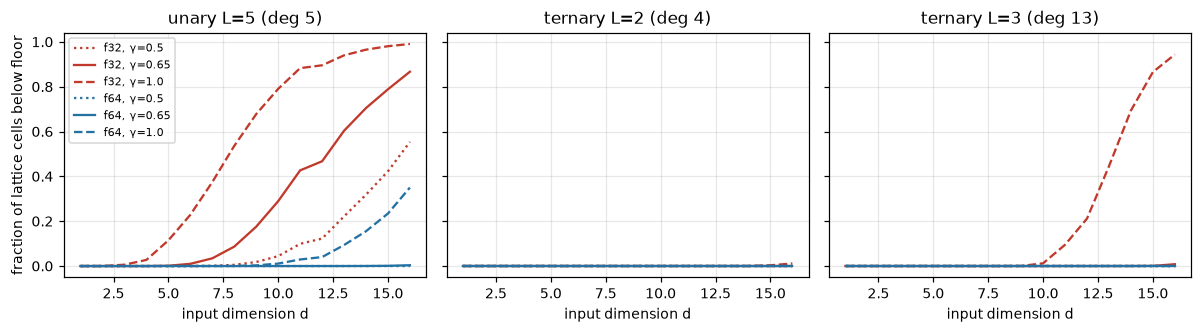

corner-cell crossing d (nominal floors, offset 0):
  unary L=5 (deg 5)      log2 rho_corner per dim =  -7.98 | f32,γ=0.5: d*=  5.8 f32,γ=1.0: d*=  2.9 f64,γ=0.5: d*= 13.0 f64,γ=1.0: d*=  6.5
  ternary L=2 (deg 4)    log2 rho_corner per dim =  -2.00 | f32,γ=0.5: d*= 23.0 f32,γ=1.0: d*= 11.5 f64,γ=0.5: d*= 52.0 f64,γ=1.0: d*= 26.0
  ternary L=3 (deg 13)   log2 rho_corner per dim =  -3.00 | f32,γ=0.5: d*= 15.3 f32,γ=1.0: d*=  7.7 f64,γ=0.5: d*= 34.7 f64,γ=1.0: d*= 17.3


In [4]:
def frac_below(alpha_base, d, thr_log2rho, bw=0.25):
    lo = np.log2(redundancy_1d(alpha_base)[1].min() / redundancy_1d(alpha_base)[1].max()) * d - 1
    bins = np.arange(lo, bw, bw)
    acc, width = log2_rho_hist(alpha_base, d, bins)
    tot = sum(acc.values())
    below = sum(c for o, c in acc.items() if -o * width < thr_log2rho)
    return below / tot

A_ENCS = {"unary L=5 (deg 5)": ENC["unary"](5), "ternary L=2 (deg 4)": ENC["ternary"](2), "ternary L=3 (deg 13)": ENC["ternary"](3)}
rowsA = []
for name, ab in A_ENCS.items():
    _, w = redundancy_1d(ab); l1 = np.log2(w.min() / w.max())
    for d in range(1, 17):
        for gam in (0.5, 0.65, 1.0):
            for prec, fl in (("f32", -23.0), ("f64", -52.0)):
                thr = fl / gam            # log2 rho below which gamma*log2 rho < floor (offset c ~ 0)
                rowsA.append(dict(enc=name, d=d, gamma=gam, prec=prec, corner_log2rho=d * l1,
                                  corner_below=d * l1 < thr, frac_below=frac_below(ab, d, thr)))
A = pd.DataFrame(rowsA); A.to_csv(f"{RESULTS_DIR}/partA_theory.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(11, 3.1), sharey=True)
for ax, (name, _) in zip(axs, A_ENCS.items()):
    for prec in ("f32", "f64"):
        for gam, ls in ((0.5, ":"), (0.65, "-"), (1.0, "--")):
            s = A[(A.enc == name) & (A.prec == prec) & (A.gamma == gam)]
            ax.plot(s.d, s.frac_below, ls, color=COL[prec], label=f"{prec}, γ={gam}")
    ax.set_title(name); ax.set_xlabel("input dimension d")
axs[0].set_ylabel("fraction of lattice cells below floor"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figA_fraction_below.pdf"); plt.show()

print("corner-cell crossing d (nominal floors, offset 0):")
for name, ab in A_ENCS.items():
    _, w = redundancy_1d(ab); l1 = np.log2(w.min() / w.max())
    print(f"  {name:<22} log2 rho_corner per dim = {l1:6.2f} | " +
          " ".join(f"{p},γ={g}: d*={fl/(g*l1):5.1f}" for p, fl in (("f32", -23), ("f64", -52)) for g in (0.5, 1.0)))

## Part B — measured coefficient-Jacobian magnitudes and the precision floor

For each $(\text{enc}, d, L)$ and random $\theta\sim U[0,2\pi]$: evaluate $\partial f/\partial\theta$ on an oversampled grid $M=2K+3$ **entirely in the given precision**, FFT to coefficient tangents, take row norms $r_\omega$. Cells with $|\omega_i|=K+1$ are out of band: zero in exact arithmetic, so their median row norm *is* the noise floor of that precision.

- **Fit** (f64, cells with SNR > 10): $\log_2(r_\omega/r_{\max}) = c + \gamma\log_2\rho_\omega$, pooled and per seed.
- **Predicted threshold** per precision: $t_p = (\log_2 F_p - c)/\gamma$, where $F_p$ is the measured relative floor.
- **Measured threshold** per precision: the $\log_2\rho$ bin where the median $r_\omega/\text{floor}$ drops below `SNR_RESOLVED`.
- **Precision-shift test:** the same $(c,\gamma)$ must predict the threshold in f32 *and* f64. This is a prediction about a *ratio*, so it does not hinge on prefactors.

In [5]:
import pickle
B_CACHE = f"{RESULTS_DIR}/partB_cells.pkl"
Bcells = pickle.load(open(B_CACHE, "rb")) if os.path.exists(B_CACHE) else {}
for enc, d, L in PARTB_CONFIGS:
    ab = ENC[enc](L)
    for s in range(PARTB_SEEDS):
        for prec in ("f64", "f32"):
            key = (enc, d, L, s, prec)
            if key in Bcells: continue
            t0 = time.time()
            th = init_theta(jax.random.PRNGKey(1000 * d + 10 * L + s), L, d, jnp.float64)
            al = alpha_array(ab, d, jnp.float64)
            F, r, inb, _ = coeff_jacobian_rows(th, al, prec)
            lr = cell_log2_rho_on_grid(F, ab)
            rmax = r[inb].max(); floor = np.median(r[~inb])
            Bcells[key] = dict(log2rho=lr[inb].astype(np.float32),
                               log2r=np.log2(r[inb] / rmax).astype(np.float32),
                               log2floor=float(np.log2(floor / rmax)))
            pickle.dump(Bcells, open(B_CACHE, "wb"))
            print(f"{enc:<8} d={d} L={L:<3} seed={s} {prec}: floor 2^{Bcells[key]['log2floor']:.1f}, "
                  f"{inb.sum()} cells, {time.time()-t0:.1f}s")

unary    d=1 L=3   seed=0 f64: floor 2^-52.7, 7 cells, 0.8s
unary    d=1 L=3   seed=0 f32: floor 2^-23.3, 7 cells, 0.5s
unary    d=1 L=3   seed=1 f64: floor 2^-51.4, 7 cells, 0.0s
unary    d=1 L=3   seed=1 f32: floor 2^-22.7, 7 cells, 0.0s
unary    d=1 L=3   seed=2 f64: floor 2^-52.2, 7 cells, 0.0s
unary    d=1 L=3   seed=2 f32: floor 2^-23.2, 7 cells, 0.0s
unary    d=1 L=3   seed=3 f64: floor 2^-51.9, 7 cells, 0.0s
unary    d=1 L=3   seed=3 f32: floor 2^-22.5, 7 cells, 0.0s
unary    d=1 L=3   seed=4 f64: floor 2^-50.9, 7 cells, 0.0s
unary    d=1 L=3   seed=4 f32: floor 2^-22.6, 7 cells, 0.0s
unary    d=1 L=3   seed=5 f64: floor 2^-52.4, 7 cells, 0.0s
unary    d=1 L=3   seed=5 f32: floor 2^-24.2, 7 cells, 0.0s
unary    d=1 L=5   seed=0 f64: floor 2^-51.0, 11 cells, 0.7s
unary    d=1 L=5   seed=0 f32: floor 2^-22.4, 11 cells, 0.6s
unary    d=1 L=5   seed=1 f64: floor 2^-51.3, 11 cells, 0.0s
unary    d=1 L=5   seed=1 f32: floor 2^-22.2, 11 cells, 0.0s
unary    d=1 L=5   seed=2 f64: floor

In [6]:
# ---- (1) power-law fit on resolved f64 cells; per-config/seed spread ----
def fit_line(keys, snr=10.0, rho_range=(-np.inf, np.inf)):
    xs, ys = [], []
    for k in keys:
        v = Bcells[k]
        m = (v["log2r"] > v["log2floor"] + np.log2(snr)) & (v["log2rho"] >= rho_range[0]) & (v["log2rho"] < rho_range[1])
        xs.append(v["log2rho"][m]); ys.append(v["log2r"][m])
    x, y = np.concatenate(xs), np.concatenate(ys)
    if len(x) < 5 or np.ptp(x) < 1: return np.nan, np.nan, np.nan, len(x), np.nan
    g, c = np.polyfit(x, y, 1); res = y - (g * x + c)
    return g, c, res.std(), len(x), 1 - res.var() / y.var()

fits = {}
for enc in sorted({k[0] for k in Bcells}):
    k64 = [k for k in Bcells if k[0] == enc and k[4] == "f64"]
    g, c, sd, n, r2 = fit_line(k64)
    per = [fit_line([k])[0] for k in k64]
    rho_span = np.ptp(np.concatenate([Bcells[k]["log2rho"] for k in k64]))
    fits[enc] = dict(gamma=g, c=c, resid_sd=sd, n=n, r2=r2, rho_span=rho_span,
                     gamma_q25=np.nanpercentile(per, 25), gamma_q75=np.nanpercentile(per, 75))
    print(f"{enc:<8} pooled gamma = {g:.3f}, c = {c:.2f}, R^2 = {r2:.3f}, residual sd = {sd:.2f} bits (n={n}); "
          f"per-config/seed gamma IQR [{fits[enc]['gamma_q25']:.2f}, {fits[enc]['gamma_q75']:.2f}]; log2 rho span {rho_span:.0f} bits")
    if rho_span < 15: print(f"   WARNING: {enc} spans only {rho_span:.0f} bits of rho -> slope poorly constrained, do not extrapolate")
# curvature check: local slopes in shallow / mid / deep rho ranges
for rng in [(-20, 0), (-45, -20), (-np.inf, -45)]:
    g, c, sd, n, _ = fit_line([k for k in Bcells if k[0] == "unary" and k[4] == "f64"], rho_range=rng)
    print(f"   unary local slope on log2 rho in {rng}: gamma = {g:.2f} (n={n})")

# dimension offset: log2 r = c + gamma*log2 rho + beta*d  (beta < 0 = extra per-dimension penalty beyond redundancy,
# e.g. a Hilbert-space-dimension factor). If beta is clearly non-zero, rho alone does NOT collapse the d-curves and the
# degree-5 extrapolation in d must use (gamma, beta), not gamma alone.
def fit_with_d(enc, snr=10.0):
    X, Y = [], []
    for k, v in Bcells.items():
        if k[0] != enc or k[4] != "f64": continue
        m = v["log2r"] > v["log2floor"] + np.log2(snr)
        X.append(np.stack([np.ones(m.sum()), v["log2rho"][m], np.full(m.sum(), k[1])], 1)); Y.append(v["log2r"][m])
    X, Y = np.concatenate(X), np.concatenate(Y)
    if np.ptp(X[:, 2]) == 0: return None
    coef, *_ = np.linalg.lstsq(X, Y, rcond=None)
    return dict(c=coef[0], gamma=coef[1], beta=coef[2], resid_sd=np.std(Y - X @ coef))
fitd = fit_with_d("unary")
if fitd: print(f"unary with dimension offset: gamma = {fitd['gamma']:.2f}, beta = {fitd['beta']:+.2f} bits/dim, "
               f"c = {fitd['c']:.2f}, residual sd {fitd['resid_sd']:.2f} bits")

floors = {p: np.median([v["log2floor"] for k, v in Bcells.items() if k[4] == p]) for p in ("f32", "f64")}
print("measured relative floors: " + ", ".join(f"{p}: 2^{floors[p]:.1f}" for p in floors))

# ---- (2) binned curves: per precision SNR, and the f64 magnitude curve (model-free reference) ----
def binned(enc, prec, field, bw=2.0, d=None):
    xs, ys = [], []
    for k, v in Bcells.items():
        if k[0] == enc and k[4] == prec and (d is None or k[1] == d):
            xs.append(v["log2rho"])
            ys.append(v["log2r"] - (v["log2floor"] if field == "snr" else 0.0))
    x, y = np.concatenate(xs), np.concatenate(ys)
    edges = np.arange(np.floor(x.min()), bw, bw)
    cen, med = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (x >= lo) & (x < hi)
        if m.sum() >= 3: cen.append((lo + hi) / 2); med.append(np.median(y[m]))
    return np.array(cen), np.array(med)

def first_crossing(cen, med, level):
    # scanning from rho = 1 downwards: first bin whose median is below `level`
    order = np.argsort(-cen)
    for i in order:
        if med[i] < level: return cen[i]
    return np.nan

def logistic_threshold(x, y):
    # 1-D logistic fit P(resolved | log2 rho); returns (rho at P=0.5, width between P=0.1 and 0.9). numpy Newton/IRLS
    if y.all() or (~y).all(): return np.nan, np.nan
    xm, xs = x.mean(), x.std() + 1e-12; z = (x - xm) / xs
    w = np.zeros(2)
    for _ in range(100):
        p = 1 / (1 + np.exp(-(w[0] + w[1] * z)))
        g = np.array([np.sum(y - p), np.sum((y - p) * z)])
        H = np.array([[np.sum(p * (1 - p)), np.sum(p * (1 - p) * z)], [0, np.sum(p * (1 - p) * z * z)]]); H[1, 0] = H[0, 1]
        step = np.linalg.solve(H + 1e-9 * np.eye(2), g); w += step
        if np.abs(step).max() < 1e-8: break
    if w[1] <= 0: return np.nan, np.nan
    x50 = xm + xs * (-w[0] / w[1]); width = xs * (2 * np.log(9)) / w[1]
    return x50, width

def resolved_cells(enc, prec):
    xs, ys = [], []
    for k, v in Bcells.items():
        if k[0] == enc and k[4] == prec:
            xs.append(v["log2rho"]); ys.append(v["log2r"] > v["log2floor"] + np.log2(SNR_RESOLVED))
    return np.concatenate(xs), np.concatenate(ys)

rho_min = min(v["log2rho"].min() for k, v in Bcells.items() if k[0] == "unary")
thr = {}
for prec in ("f32", "f64"):
    f = fits["unary"]
    x, y = resolved_cells("unary", prec)
    x50, width = logistic_threshold(x, y)
    cen, med = binned("unary", prec, "snr")
    thr[prec] = dict(meas=x50, width=width, pred_line=(floors[prec] + np.log2(SNR_RESOLVED) - f["c"]) / f["gamma"],
                     n_lost=int((~y).sum()), centers=cen, med=med, reached=bool((~y).sum() >= 5))
    t = thr[prec]
    print(f"{prec}: 50% resolved at log2 rho = {t['meas']:6.1f} (10-90% width {t['width']:.1f} bits, "
          f"{t['n_lost']} unresolved cells) | power-law prediction {t['pred_line']:6.1f}"
          + ("" if t["reached"] else "  <- too few unresolved cells: extend PARTB_CONFIGS"))

# ---- (3) model-free precision test for f32: is a cell resolved in f32 exactly when its f64 magnitude is above the f32 floor? ----
tp = fp = fn = tn = 0; wrong_mag = 0
for k, v in Bcells.items():
    if k[4] != "f32" or k[0] != "unary": continue
    v64 = Bcells[k[:4] + ("f64",)]
    above = v64["log2r"] > v["log2floor"] + np.log2(SNR_RESOLVED)          # f64 says: above the f32 floor
    ok32 = (v["log2r"] > v["log2floor"] + np.log2(SNR_RESOLVED)) & (np.abs(v["log2r"] - v64["log2r"]) < 1)
    tp += np.sum(above & ok32); fn += np.sum(above & ~ok32); fp += np.sum(~above & ok32); tn += np.sum(~above & ~ok32)
print(f"f32 resolvability vs f64-predicted: agree {(tp+tn)/(tp+tn+fp+fn):.3f} | "
      f"predicted-resolved but lost {fn} | predicted-lost but resolved {fp} | (n={tp+tn+fp+fn})")
precision_test = dict(agree=(tp + tn) / max(1, tp + tn + fp + fn), fn=int(fn), fp=int(fp))

ternary  pooled gamma = 0.291, c = -6.14, R^2 = 0.009, residual sd = 4.46 bits (n=149082); per-config/seed gamma IQR [-0.31, 0.42]; log2 rho span 9 bits
unary    pooled gamma = 0.623, c = 0.82, R^2 = 0.896, residual sd = 1.98 bits (n=1977260); per-config/seed gamma IQR [0.56, 0.80]; log2 rho span 96 bits
   unary local slope on log2 rho in (-20, 0): gamma = 0.56 (n=1353804)
   unary local slope on log2 rho in (-45, -20): gamma = 0.66 (n=596442)
   unary local slope on log2 rho in (-inf, -45): gamma = 0.68 (n=26852)
unary with dimension offset: gamma = 0.62, beta = -0.04 bits/dim, c = 1.02, residual sd 1.98 bits
measured relative floors: f32: 2^-23.3, f64: 2^-52.3
f32: 50% resolved at log2 rho =  -38.0 (10-90% width 11.3 bits, 76917 unresolved cells) | power-law prediction  -36.2
f64: 50% resolved at log2 rho =  -74.1 (10-90% width 15.9 bits, 956 unresolved cells) | power-law prediction  -82.6
f32 resolvability vs f64-predicted: agree 0.999 | predicted-resolved but lost 5 | predicted-lo

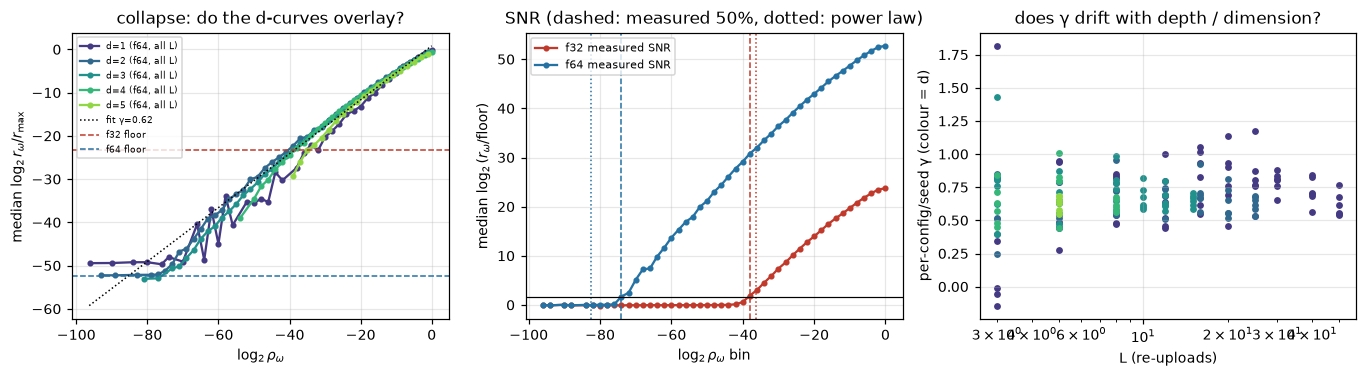

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.5))
ax = axs[0]
ds = sorted({k[1] for k in Bcells if k[0] == "unary"})
for d in ds:
    cen, med = binned("unary", "f64", "mag", d=d)
    ax.plot(cen, med, "o-", ms=3, color=plt.cm.viridis(d / (max(ds) + 1)), label=f"d={d} (f64, all L)")
xx = np.linspace(min(v["log2rho"].min() for v in Bcells.values()), 0, 50)
ax.plot(xx, fits["unary"]["c"] + fits["unary"]["gamma"] * xx, "k:", lw=1, label=f"fit γ={fits['unary']['gamma']:.2f}")
for p in floors: ax.axhline(floors[p], color=COL[p], ls="--", lw=1, label=f"{p} floor")
ax.set_xlabel(r"$\log_2\rho_\omega$"); ax.set_ylabel(r"median $\log_2 r_\omega/r_{\max}$"); ax.legend(fontsize=6)
ax.set_title("collapse: do the d-curves overlay?")

ax = axs[1]
for p in ("f32", "f64"):
    ax.plot(thr[p]["centers"], thr[p]["med"], "o-", ms=3, color=COL[p], label=f"{p} measured SNR")
    if np.isfinite(thr[p]["meas"]): ax.axvline(thr[p]["meas"], color=COL[p], ls="--", lw=1)
    ax.axvline(thr[p]["pred_line"], color=COL[p], ls=":", lw=1)
ax.axhline(np.log2(SNR_RESOLVED), color="k", lw=0.8)
ax.set_xlabel(r"$\log_2\rho_\omega$ bin"); ax.set_ylabel(r"median $\log_2(r_\omega/\mathrm{floor})$")
ax.set_title("SNR (dashed: measured 50%, dotted: power law)"); ax.legend(fontsize=7)

ax = axs[2]
for (enc, d, L) in sorted({k[:3] for k in Bcells}):
    if enc != "unary": continue
    g = [fit_line([k])[0] for k in Bcells if k[:3] == (enc, d, L) and k[4] == "f64"]
    ax.scatter([L] * len(g), g, s=12, color=plt.cm.viridis(d / (max(ds) + 1)))
ax.set_xscale("log"); ax.set_xlabel("L (re-uploads)"); ax.set_ylabel("per-config/seed γ (colour = d)")
ax.set_title("does γ drift with depth / dimension?")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figB_collapse.pdf"); plt.show()

### Part B3 — predicted limit at fixed degree

$d^*$ at which the corner cell, 1 % and 50 % of all lattice cells fall below `SNR_RESOLVED` × floor, from several threshold estimates: the power law **with a per-dimension offset** $\beta$ (the row to trust if $\beta$ is clearly non-zero, because then $\rho$ alone does not collapse the $d$-curves), the **measured** 50 %-resolved point (logistic fit of resolved vs $\log_2\rho$; only where the $(d,L)$ grid reaches that deep), a power law fitted only on deep cells ($\log_2\rho<-20$, where the extrapolation lives), and the pooled power law with $\gamma$ at the per-seed quartiles (a band, not a point).

Ternary is evaluated with the *unary* law as well, because the ternary $\rho$-range per cell is too narrow to fit its own slope. Treat the ternary rows as "what the redundancy law would imply", not as a measured result: whether ternary magnitudes follow redundancy at all is itself open (the fitted ternary slope is reported above).

In [8]:
def dstar_from_threshold(alpha_base, thr_rho, dmax=40):
    _, w = redundancy_1d(alpha_base); l1 = np.log2(w.min() / w.max())
    out = {"corner": thr_rho / l1 if np.isfinite(thr_rho) else np.nan}
    for q in (0.01, 0.5):
        out[f"{int(q*100)}%"] = (next((d for d in range(1, dmax + 1) if frac_below(alpha_base, d, thr_rho) >= q), np.inf)
                                 if np.isfinite(thr_rho) else np.nan)
    return out

f = fits["unary"]
f_deep = fit_line([k for k in Bcells if k[0] == "unary" and k[4] == "f64"], rho_range=(-np.inf, -20))[:2]
print(f"deep local power law (log2 rho < -20): gamma = {f_deep[0]:.2f}, c = {f_deep[1]:.2f}")
rowsP = []
for name, ab in (("unary deg 5 (L=5)", ENC["unary"](5)), ("ternary deg 4 (L=2)", ENC["ternary"](2)),
                 ("ternary deg 13 (L=3)", ENC["ternary"](3))):
    for prec in ("f32", "f64"):
        if fitd:   # d-dependent threshold: c + gamma*log2rho + beta*d = floor + log2 SNR
            lv = floors[prec] + np.log2(SNR_RESOLVED) - fitd["c"]
            _, w = redundancy_1d(ab); l1 = np.log2(w.min() / w.max())
            row = dict(encoding=name, prec=prec, threshold_from="power law + d-offset (γ, β)", thr_log2rho=np.nan,
                       corner=lv / (fitd["gamma"] * l1 + fitd["beta"]))
            for q in (0.01, 0.5):
                row[f"{int(q*100)}%"] = next((d for d in range(1, 41)
                                             if frac_below(ab, d, (lv - fitd["beta"] * d) / fitd["gamma"]) >= q), np.inf)
            rowsP.append(row)
        lvl = floors[prec] + np.log2(SNR_RESOLVED) - f["c"]
        for src, t in (("measured 50% resolved", thr[prec]["meas"] if thr[prec]["reached"] else np.nan),
                       ("power law, deep local slope", (floors[prec] + np.log2(SNR_RESOLVED) - f_deep[1]) / f_deep[0]),
                       ("power law, γ=q25", lvl / f["gamma_q25"]),
                       ("power law, γ=pooled", lvl / f["gamma"]), ("power law, γ=q75", lvl / f["gamma_q75"])):
            rowsP.append(dict(encoding=name, prec=prec, threshold_from=src, thr_log2rho=t, **dstar_from_threshold(ab, t)))
P = pd.DataFrame(rowsP); P.to_csv(f"{RESULTS_DIR}/partB3_predicted_dstar.csv", index=False)
print(P.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

deep local power law (log2 rho < -20): gamma = 0.68, c = 2.42
            encoding prec              threshold_from  thr_log2rho  corner   1%  50%
   unary deg 5 (L=5)  f32 power law + d-offset (γ, β)          NaN     4.5  7.0 13.0
   unary deg 5 (L=5)  f32       measured 50% resolved        -38.0     4.8  7.0 13.0
   unary deg 5 (L=5)  f32 power law, deep local slope        -35.5     4.5  7.0 13.0
   unary deg 5 (L=5)  f32            power law, γ=q25        -40.3     5.1  8.0 14.0
   unary deg 5 (L=5)  f32         power law, γ=pooled        -36.2     4.5  7.0 13.0
   unary deg 5 (L=5)  f32            power law, γ=q75        -28.3     3.5  5.0 10.0
   unary deg 5 (L=5)  f64 power law + d-offset (γ, β)          NaN    10.3 18.0 28.0
   unary deg 5 (L=5)  f64       measured 50% resolved        -74.1     9.3 16.0 26.0
   unary deg 5 (L=5)  f64 power law, deep local slope        -78.2     9.8 17.0 27.0
   unary deg 5 (L=5)  f64            power law, γ=q25        -92.1    11.5 21.0 31.0
   

## Part C — does the floor bind *training*, and are trainable frequencies worth it?

**Main sweep:** 4 arms {unary, ternary} × {fixed, trainable prefactors} × $d$ × targets {T1 lattice teacher, T2 off-lattice teacher} × init {near, random} × precision × optimiser; seeds run in parallel (vmapped). Test error is evaluated in f64 so it reports what was *learned*, not the evaluation precision.

**Stress configs** (`C_STRESS`): unary, fixed, T1, near-init at $(d,L)$ where Part B says the f32 floor binds. Per-cell improvement $\lvert\Delta c^{\rm final}_\omega\rvert/\lvert\Delta c^{\rm init}_\omega\rvert$ (f64 coefficients of the trained parameters) binned by $\rho$. Expected if the floor binds training: f32 ratio ≈ 1 below the threshold, f64 < 1. With near-init perturbation $\sigma$, the training threshold should sit about $\log_2(1/\sigma)/\gamma$ bits of $\rho$ above the Part-B threshold (a cell must carry a residual above the absolute rounding level of $f$).

Caveats built into the design: ternary arms have fewer gates and parameters than unary (matched degree, not matched size); T1 uses a teacher of the same encoding as the student; GD learning rate is a first guess.

In [9]:
C_CSV = f"{RESULTS_DIR}/partC_runs.csv"
C_CELLS = f"{RESULTS_DIR}/partC_cells.pkl"
done = pd.read_csv(C_CSV) if os.path.exists(C_CSV) else pd.DataFrame()
cells_store = pickle.load(open(C_CELLS, "rb")) if os.path.exists(C_CELLS) else {}
done_keys = set(done["key"]) if len(done) else set()

def run_one(arm, d, L, target, init, prec, opt, lr, enc, trainable, tag):
    key = f"{tag}|{arm}|d{d}|L{L}|{target}|{init}|{prec}|{opt}"
    if key in done_keys: return
    t0 = time.time()
    ks = jax.random.split(jax.random.PRNGKey(SEED0 + 7919 * d + 31 * L), 4 * C_SEEDS).reshape(C_SEEDS, 4, 2)
    T = [make_teacher(ks[i, 0], enc, L, d, target == "T2", T2_JITTER) for i in range(C_SEEDS)]
    Xtr = jnp.stack([jax.random.uniform(ks[i, 1], (C_NTRAIN, d), minval=0, maxval=2*np.pi, dtype=jnp.float64) for i in range(C_SEEDS)])
    Xte = jnp.stack([jax.random.uniform(ks[i, 2], (C_NTEST, d), minval=0, maxval=2*np.pi, dtype=jnp.float64) for i in range(C_SEEDS)])
    ytr = jnp.stack([model_batch(Xtr[i], *T[i]) for i in range(C_SEEDS)])
    yte = jnp.stack([model_batch(Xte[i], *T[i]) for i in range(C_SEEDS)])
    S0 = [student_init(ks[i, 3], T[i][0], enc, L, d, init, C_SIGMA) for i in range(C_SEEDS)]
    p0 = {"theta": jnp.stack([s[0] for s in S0]), "alpha": jnp.stack([s[1] for s in S0])}
    alf = p0["alpha"]
    p, hist = train_batch(p0, Xtr, ytr, alf, trainable, opt, lr, C_STEPS, prec)
    var = np.asarray(jnp.var(yte, axis=1))
    te = eval_f64(p, Xte, yte, alf, trainable) / var
    te0 = eval_f64(p0, Xte, yte, alf, trainable) / var
    row = dict(key=key, tag=tag, arm=arm, enc=enc, trainable=trainable, d=d, L=L, target=target, init=init,
               prec=prec, opt=opt, lr=lr, steps=C_STEPS, secs=time.time() - t0,
               test_nmse_med=float(np.median(te)), test_nmse_min=float(np.min(te)), test_nmse_max=float(np.max(te)),
               test_nmse_init_med=float(np.median(te0)),
               train_loss_final_med=float(np.median(hist[-1][1])))
    # per-cell improvement: only valid when student and teacher spectra sit on the integer lattice
    if target == "T1" and not trainable and (2 * degree(ENC[enc](L)) + 1) ** d <= 200_000:
        imp, lrho = [], None
        for i in range(C_SEEDS):
            F, ct = coeffs_f64(*T[i]); _, c0 = coeffs_f64(p0["theta"][i], alf[i]); _, c1 = coeffs_f64(p["theta"][i], alf[i])
            lrho = cell_log2_rho_on_grid(F, ENC[enc](L)).ravel()
            imp.append(np.log2(np.abs(c1 - ct).ravel() / np.maximum(np.abs(c0 - ct).ravel(), 1e-300)))
        entry = dict(log2rho=lrho, log2imp=np.median(np.stack(imp), axis=0), hist=hist)
        if tag == "stress":   # actual f64 tangent magnitude of each cell at the student init (model-free x-axis)
            lr_init = []
            for i in range(C_SEEDS):
                Fj, rj, inb, _ = coeff_jacobian_rows(p0["theta"][i], alf[i], "f64")
                K = degree(ENC[enc](L))
                lin_j = np.ravel_multi_index(tuple(np.moveaxis(Fj[inb] + K, -1, 0)), (2 * K + 1,) * d)
                lin_c = np.ravel_multi_index(tuple(np.moveaxis(F.reshape(-1, d) + K, -1, 0)), (2 * K + 1,) * d)
                lookup = np.full((2 * K + 1) ** d, np.nan); lookup[lin_j] = np.log2(rj[inb] / rj[inb].max())
                lr_init.append(lookup[lin_c])
            entry["log2r_init"] = np.median(np.stack(lr_init), axis=0)
        cells_store[key] = entry
        pickle.dump(cells_store, open(C_CELLS, "wb"))
    pd.DataFrame([row]).to_csv(C_CSV, mode="a", header=not os.path.exists(C_CSV), index=False)
    done_keys.add(key)
    print(f"{key:<58} test nMSE med {row['test_nmse_med']:.2e} (init {row['test_nmse_init_med']:.2e}) {row['secs']:.0f}s")

# stress configs first (mechanism), then the main sweep
for (d, L) in C_STRESS:
    for prec in C_PRECS:
        for opt, lr in C_OPTS.items():
            run_one("unary_fixed", d, L, "T1", "near", prec, opt, lr, "unary", False, "stress")
for d in C_DIMS:
    for arm, (enc, L, trainable) in ARMS.items():
        for target in ("T1", "T2"):
            for init in C_INITS:
                for prec in C_PRECS:
                    for opt, lr in C_OPTS.items():
                        run_one(arm, d, L, target, init, prec, opt, lr, enc, trainable, "main")

stress|unary_fixed|d1|L30|T1|near|f32|adam                 test nMSE med 1.12e-05 (init 3.94e-01) 67s
stress|unary_fixed|d1|L30|T1|near|f32|gd                   test nMSE med 1.06e-04 (init 3.94e-01) 78s
stress|unary_fixed|d1|L30|T1|near|f64|adam                 test nMSE med 1.20e-05 (init 3.94e-01) 67s
stress|unary_fixed|d1|L30|T1|near|f64|gd                   test nMSE med 1.06e-04 (init 3.94e-01) 77s
stress|unary_fixed|d2|L12|T1|near|f32|adam                 test nMSE med 1.82e-06 (init 3.46e-01) 67s
stress|unary_fixed|d2|L12|T1|near|f32|gd                   test nMSE med 2.97e-04 (init 3.46e-01) 71s
stress|unary_fixed|d2|L12|T1|near|f64|adam                 test nMSE med 2.36e-06 (init 3.46e-01) 71s
stress|unary_fixed|d2|L12|T1|near|f64|gd                   test nMSE med 2.97e-04 (init 3.46e-01) 81s
stress|unary_fixed|d3|L8|T1|near|f32|adam                  test nMSE med 2.50e-08 (init 3.68e-01) 81s
stress|unary_fixed|d3|L8|T1|near|f32|gd                    test nMSE med 2.14e-04 

/var/folders/g_/sjmkkkwx0m9b19mf8mrnv3l40000gn/T/ipykernel_18199/2670990140.py:35: RuntimeWarning: divide by zero encountered in log2
  imp.append(np.log2(np.abs(c1 - ct).ravel() / np.maximum(np.abs(c0 - ct).ravel(), 1e-300)))


main|ternary_fixed|d2|L2|T1|near|f32|adam                  test nMSE med 9.08e-09 (init 5.97e-02) 10s
main|ternary_fixed|d2|L2|T1|near|f32|gd                    test nMSE med 2.75e-05 (init 5.97e-02) 10s
main|ternary_fixed|d2|L2|T1|near|f64|adam                  test nMSE med 3.10e-12 (init 5.97e-02) 11s
main|ternary_fixed|d2|L2|T1|near|f64|gd                    test nMSE med 2.74e-05 (init 5.97e-02) 11s
main|ternary_fixed|d2|L2|T1|random|f32|adam                test nMSE med 5.58e-02 (init 2.16e+00) 10s
main|ternary_fixed|d2|L2|T1|random|f32|gd                  test nMSE med 1.02e-01 (init 2.16e+00) 10s
main|ternary_fixed|d2|L2|T1|random|f64|adam                test nMSE med 5.58e-02 (init 2.16e+00) 11s
main|ternary_fixed|d2|L2|T1|random|f64|gd                  test nMSE med 1.02e-01 (init 2.16e+00) 11s
main|ternary_fixed|d2|L2|T2|near|f32|adam                  test nMSE med 5.39e-01 (init 1.84e+00) 10s
main|ternary_fixed|d2|L2|T2|near|f32|gd                    test nMSE med 5.57e-01 

/var/folders/g_/sjmkkkwx0m9b19mf8mrnv3l40000gn/T/ipykernel_18199/2670990140.py:35: RuntimeWarning: divide by zero encountered in log2
  imp.append(np.log2(np.abs(c1 - ct).ravel() / np.maximum(np.abs(c0 - ct).ravel(), 1e-300)))


main|ternary_fixed|d3|L2|T1|near|f64|adam                  test nMSE med 5.44e-15 (init 9.35e-02) 20s
main|ternary_fixed|d3|L2|T1|near|f64|gd                    test nMSE med 3.57e-05 (init 9.35e-02) 21s
main|ternary_fixed|d3|L2|T1|random|f32|adam                test nMSE med 1.92e-01 (init 1.79e+00) 19s
main|ternary_fixed|d3|L2|T1|random|f32|gd                  test nMSE med 9.27e-01 (init 1.79e+00) 19s


/var/folders/g_/sjmkkkwx0m9b19mf8mrnv3l40000gn/T/ipykernel_18199/2670990140.py:35: RuntimeWarning: divide by zero encountered in log2
  imp.append(np.log2(np.abs(c1 - ct).ravel() / np.maximum(np.abs(c0 - ct).ravel(), 1e-300)))


main|ternary_fixed|d3|L2|T1|random|f64|adam                test nMSE med 1.92e-01 (init 1.79e+00) 20s
main|ternary_fixed|d3|L2|T1|random|f64|gd                  test nMSE med 9.27e-01 (init 1.79e+00) 21s
main|ternary_fixed|d3|L2|T2|near|f32|adam                  test nMSE med 7.37e-01 (init 1.88e+00) 18s
main|ternary_fixed|d3|L2|T2|near|f32|gd                    test nMSE med 7.61e-01 (init 1.88e+00) 19s
main|ternary_fixed|d3|L2|T2|near|f64|adam                  test nMSE med 7.37e-01 (init 1.88e+00) 20s
main|ternary_fixed|d3|L2|T2|near|f64|gd                    test nMSE med 7.61e-01 (init 1.88e+00) 21s
main|ternary_fixed|d3|L2|T2|random|f32|adam                test nMSE med 7.72e-01 (init 1.82e+00) 18s
main|ternary_fixed|d3|L2|T2|random|f32|gd                  test nMSE med 9.14e-01 (init 1.82e+00) 19s
main|ternary_fixed|d3|L2|T2|random|f64|adam                test nMSE med 7.72e-01 (init 1.82e+00) 20s
main|ternary_fixed|d3|L2|T2|random|f64|gd                  test nMSE med 9.14e-01 

/var/folders/g_/sjmkkkwx0m9b19mf8mrnv3l40000gn/T/ipykernel_18199/2670990140.py:35: RuntimeWarning: divide by zero encountered in log2
  imp.append(np.log2(np.abs(c1 - ct).ravel() / np.maximum(np.abs(c0 - ct).ravel(), 1e-300)))


main|ternary_fixed|d5|L2|T1|near|f32|gd                    test nMSE med 3.55e-03 (init 2.18e-01) 59s
main|ternary_fixed|d5|L2|T1|near|f64|adam                  test nMSE med 9.18e-10 (init 2.18e-01) 60s
main|ternary_fixed|d5|L2|T1|near|f64|gd                    test nMSE med 3.55e-03 (init 2.18e-01) 64s
main|ternary_fixed|d5|L2|T1|random|f32|adam                test nMSE med 1.07e+00 (init 2.30e+00) 58s
main|ternary_fixed|d5|L2|T1|random|f32|gd                  test nMSE med 1.08e+00 (init 2.30e+00) 58s
main|ternary_fixed|d5|L2|T1|random|f64|adam                test nMSE med 1.07e+00 (init 2.30e+00) 60s
main|ternary_fixed|d5|L2|T1|random|f64|gd                  test nMSE med 1.08e+00 (init 2.30e+00) 62s
main|ternary_fixed|d5|L2|T2|near|f32|adam                  test nMSE med 9.93e-01 (init 2.00e+00) 57s
main|ternary_fixed|d5|L2|T2|near|f32|gd                    test nMSE med 1.07e+00 (init 2.00e+00) 58s
main|ternary_fixed|d5|L2|T2|near|f64|adam                  test nMSE med 9.93e-01 

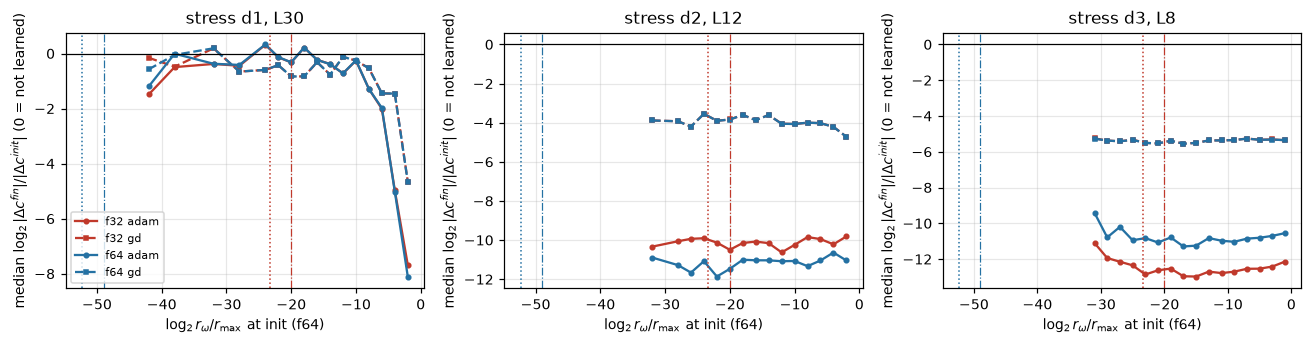

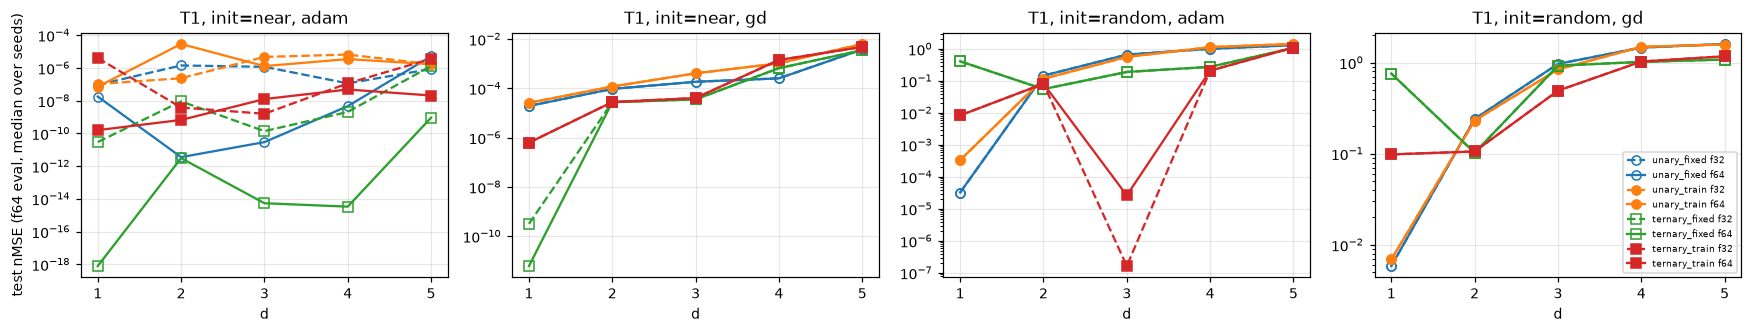

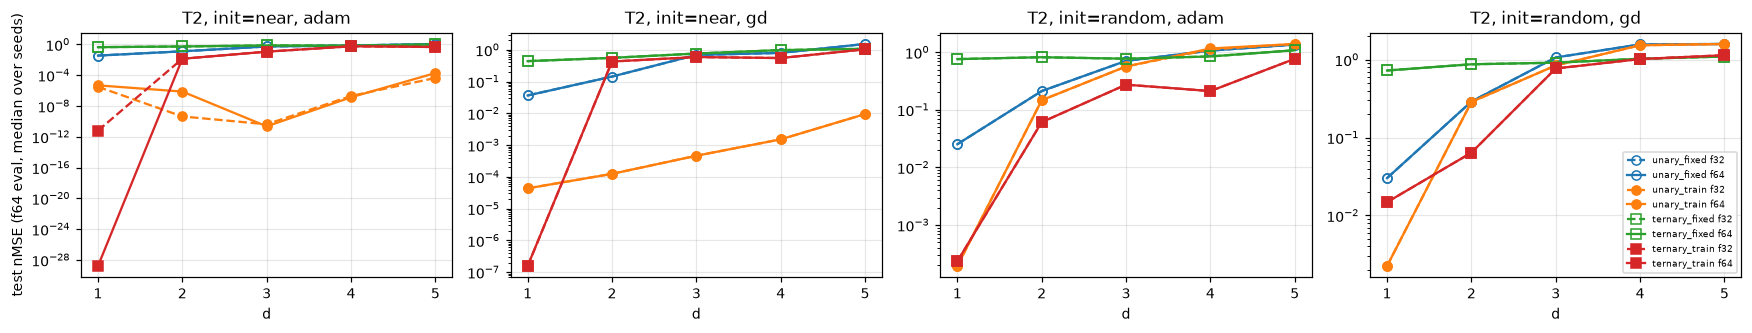

In [10]:
R = pd.read_csv(C_CSV)
# ---- stress: per-cell improvement vs actual tangent magnitude at init ----
def train_thr(prec):   # rough guide: a cell is learnable if its init residual ~ sigma * r_omega exceeds the floor
    return floors[prec] - np.log2(C_SIGMA)
st = [(k, v) for k, v in cells_store.items() if k.startswith("stress")]
if st:
    cfgs = sorted({tuple(k.split("|")[2:4]) for k, _ in st})
    fig, axs = plt.subplots(1, len(cfgs), figsize=(4 * len(cfgs), 3.2), squeeze=False)
    for ax, cfg in zip(axs[0], cfgs):
        for k, v in st:
            parts = k.split("|")
            if tuple(parts[2:4]) != cfg: continue
            prec, opt = parts[6], parts[7]
            x, y = v["log2r_init"], v["log2imp"]; ok = np.isfinite(x) & np.isfinite(y)
            x, y = x[ok], y[ok]
            edges = np.arange(np.floor(x.min()), 1, 2.0)
            cm = [((x >= a) & (x < b)) for a, b in zip(edges[:-1], edges[1:])]
            cen = [(a + b) / 2 for (a, b), m in zip(zip(edges[:-1], edges[1:]), cm) if m.sum() >= 2]
            med = [np.median(y[m]) for m in cm if m.sum() >= 2]
            ax.plot(cen, med, "o-" if opt == "adam" else "s--", ms=3, color=COL[prec], label=f"{prec} {opt}")
        for p in ("f32", "f64"):
            ax.axvline(floors[p], color=COL[p], ls=":", lw=1)
            ax.axvline(train_thr(p), color=COL[p], ls="-.", lw=0.8)
        ax.axhline(0, color="k", lw=0.8)
        ax.set_title(f"stress {cfg[0]}, {cfg[1]}"); ax.set_xlabel(r"$\log_2 r_\omega/r_{\max}$ at init (f64)")
        ax.set_ylabel(r"median $\log_2|\Delta c^{fin}|/|\Delta c^{init}|$ (0 = not learned)")
    axs[0][0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figC_stress_cells.pdf"); plt.show()

# ---- main: test error vs d ----
M_ = R[R.tag == "main"]
for target in ("T1", "T2"):
    fig, axs = plt.subplots(1, len(C_INITS) * len(C_OPTS), figsize=(4 * len(C_INITS) * len(C_OPTS), 3.1), squeeze=False)
    for ax, (init, opt) in zip(axs[0], [(i, o) for i in C_INITS for o in C_OPTS]):
        for arm in ARMS:
            for prec in C_PRECS:
                s = M_[(M_.target == target) & (M_.init == init) & (M_.opt == opt) & (M_.arm == arm) & (M_.prec == prec)].sort_values("d")
                if not len(s): continue
                ax.semilogy(s.d, s.test_nmse_med, ("-" if prec == "f64" else "--"),
                            marker="o" if "unary" in arm else "s", mfc="none" if "fixed" in arm else None,
                            color=plt.cm.tab10(list(ARMS).index(arm)), label=f"{arm} {prec}")
        ax.set_title(f"{target}, init={init}, {opt}"); ax.set_xlabel("d")
    axs[0][0].set_ylabel("test nMSE (f64 eval, median over seeds)"); axs[0][-1].legend(fontsize=6)
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figC_main_{target}.pdf"); plt.show()

## Decision summary

In [11]:
print("=" * 78)
f = fits["unary"]
print(f"Q1 magnitude ~ redundancy^γ: pooled γ = {f['gamma']:.2f} (per-seed IQR {f['gamma_q25']:.2f}-{f['gamma_q75']:.2f}), "
      f"residual sd {f['resid_sd']:.2f} bits")
if fitd: print(f"   extra per-dimension offset β = {fitd['beta']:+.2f} bits/dim (|β| ≳ 1 => rho alone does not collapse the d-curves; "
               f"use the (γ, β) rows of Q3)")
if "ternary" in fits:
    print(f"   ternary γ = {fits['ternary']['gamma']:.2f} -> transfer of the unary law to ternary {'OK' if abs(fits['ternary']['gamma']-f['gamma'])<0.15 else 'QUESTIONABLE'}")
print(f"Q2a precision law, cell by cell (f32): resolved in f32 <=> f64 magnitude above the f32 floor -> agreement "
      f"{precision_test['agree']:.3f} (lost-but-predicted-resolved {precision_test['fn']}, resolved-but-predicted-lost {precision_test['fp']})")
print("    (no reference beyond f64, so the same cell-level test is impossible for f64; Q2b is the consistency check)")
for p in ("f32", "f64"):
    t = thr[p]
    if not t["reached"]:
        print(f"Q2b {p}: too few unresolved cells ({t['n_lost']}) -> threshold not measured; extend PARTB_CONFIGS deeper")
    else:
        print(f"Q2b {p}: 50% resolved at log2 rho {t['meas']:.1f} vs power law {t['pred_line']:.1f} "
              f"(Δ={t['meas'] - t['pred_line']:+.1f} bits); 10-90% transition width {t['width']:.1f} bits")
print("    a wide transition means redundancy is a soft predictor of tangent magnitude: the floor itself is sharp (Q2a),")
print("    the scatter is in magnitude-vs-rho (residual sd above)")
print("Q3 predicted limit (d*):"); print(P.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
st = {k: v for k, v in cells_store.items() if k.startswith("stress")}
if st:
    print(f"Q4 paired per-cell test: cells whose f64 init tangent is below the rough f32 training threshold "
          f"(log2 r_rel < {train_thr('f32'):.1f}); median log2 improvement (0 = not learned, <0 = learned):")
    for cfg in sorted({tuple(k.split('|')[2:4]) for k in st}):
        for opt in C_OPTS:
            res = {}
            for prec in C_PRECS:
                k = f"stress|unary_fixed|{cfg[0]}|{cfg[1]}|T1|near|{prec}|{opt}"
                if k not in st: continue
                x, y = st[k]["log2r_init"], st[k]["log2imp"]
                lo = np.isfinite(x) & (x < train_thr("f32")); hi = np.isfinite(x) & (x >= train_thr("f32"))
                res[prec] = (np.median(y[lo]) if lo.any() else np.nan, lo.sum(), np.median(y[hi]) if hi.any() else np.nan)
            line = " | ".join(f"{p}: below {r[0]:6.2f} (n={r[1]}), above {r[2]:6.2f}" for p, r in res.items())
            print(f"   {cfg[0]} {cfg[1]} {opt:<4} {line}")
    print("   floor binds training  <=>  f32 'below' ≈ 0 while f64 'below' < 0 on the SAME cells")
M_ = R[(R.tag == "main") & (R.opt == "adam")]
if len(M_):
    print("Q5 trainable vs fixed prefactors, Adam, test nMSE median (f64 training):")
    piv = M_[M_.prec == "f64"].pivot_table(index=["target", "init", "d"], columns="arm", values="test_nmse_med")
    print(piv.to_string(float_format=lambda v: f"{v:.1e}"))
print("=" * 78)

Q1 magnitude ~ redundancy^γ: pooled γ = 0.62 (per-seed IQR 0.56-0.80), residual sd 1.98 bits
   extra per-dimension offset β = -0.04 bits/dim (|β| ≳ 1 => rho alone does not collapse the d-curves; use the (γ, β) rows of Q3)
   ternary γ = 0.29 -> transfer of the unary law to ternary QUESTIONABLE
Q2a precision law, cell by cell (f32): resolved in f32 <=> f64 magnitude above the f32 floor -> agreement 0.999 (lost-but-predicted-resolved 5, resolved-but-predicted-lost 1162)
    (no reference beyond f64, so the same cell-level test is impossible for f64; Q2b is the consistency check)
Q2b f32: 50% resolved at log2 rho -38.0 vs power law -36.2 (Δ=-1.8 bits); 10-90% transition width 11.3 bits
Q2b f64: 50% resolved at log2 rho -74.1 vs power law -82.6 (Δ=+8.6 bits); 10-90% transition width 15.9 bits
    a wide transition means redundancy is a soft predictor of tangent magnitude: the floor itself is sharp (Q2a),
    the scatter is in magnitude-vs-rho (residual sd above)
Q3 predicted limit (d*):
 